In [34]:
from emg import load_emg, rectify_emg, bandpass_emg, rms_sliding_window_emg, make_mvc_stacks, normalize_emg
from pose import load_pose

import matplotlib.pyplot as plt


# Load data

In [36]:
emg_path = r"C:\Users\01ols\Desktop\Fiol Experiment Projekt HT26\Goteborg_1\emg"
pose_path = r"C:\Users\01ols\Desktop\Fiol Experiment Projekt HT26\Goteborg_1\pose"

emg_data = load_emg(emg_path)
pose_data = load_pose(pose_path)

Loading emg data from root directory "C:\Users\01ols\Desktop\Fiol Experiment Projekt HT26\Goteborg_1\emg"
Loading "A_MVC.csv"
Loading "A_MVC_LT_UPPER_TRAP.csv"
Loading "A_MVC_rest.csv"
Loading "A_R1.csv"
Loading "A_R2.csv"
Loading "B_MVC.csv"
Loading "B_R1.csv"
Loading "B_R2.csv"
Loading "C_MVC.csv"
Loading "C_R1.csv"
Loading "C_R2.csv"
Loading "J_MVC.csv"
Loading "J_MVC_RECT_ABDOMINIS.csv"
Loading "J_MVC_rest.csv"
Loading "J_R1.csv"
Loading "J_R2.csv"
Loading "K_MVC.csv"
Loading "K_R1.csv"
Loading "K_R2.csv"
Loading "L_MVC.csv"
Loading "L_R1.csv"
Loading "L_R2.csv"
Loading pose data from A_R1_blazepose.csv...
Loading pose data from A_R2_blazepose.csv...
Loading pose data from B_R1_blazepose.csv...
Loading pose data from B_R2_blazepose.csv...
Loading pose data from C_R1_blazepose.csv...
Loading pose data from C_R2_blazepose.csv...
Loading pose data from J_R1_blazepose.csv...
Loading pose data from J_R2_blazepose.csv...
Loading pose data from K_R1_blazepose.csv...
Loading pose data from

# Preprocess emg data
Preprocessing order:
1. Bandpass filter (noise removal)
2. RMS with sliding window (smoothing + full wave rectification)
3. Normalization (against MVC)

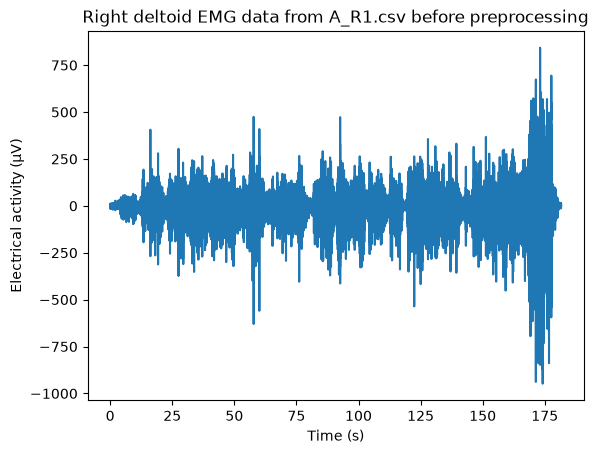

In [ ]:
# visualize EMG before preprocessing
emg_data_sample = emg_data[3].copy()
plt.plot(emg_data_sample['time'], emg_data_sample['mid_delt_rt'])
plt.xlabel("Time (s)")
plt.ylabel("Electrical activity (µV)")
plt.title(f"Right deltoid EMG data from \"{emg_data_sample['filename']}\" before preprocessing")
plt.show()

In [38]:
'''
1. Bandpass filter (noise removal)
2. RMS with sliding window (smoothing + full wave rectification)
3. Normalization (against MVC)
'''
# sampling frequency of EMG sensors is 1500 Hz
emg_data = bandpass_emg(emg_data=emg_data, freq_range=[20, 500], sample_rate=1500)
emg_data = rms_sliding_window_emg(emg_data=emg_data, window_size=75, sampling_frequency=1500)
# create MVC values for each automatically (based on file names)
mvc_stacks = make_mvc_stacks(emg_data)
# apply MVC values to all subjects (based on file names)
emg_data = normalize_emg(emg_data=emg_data, mvc_stacks=mvc_stacks)

Bandpass filtering A_MVC.csv...
Bandpass filtering A_MVC_LT_UPPER_TRAP.csv...
Bandpass filtering A_MVC_rest.csv...
Bandpass filtering A_R1.csv...
Bandpass filtering A_R2.csv...
Bandpass filtering B_MVC.csv...
Bandpass filtering B_R1.csv...
Bandpass filtering B_R2.csv...
Bandpass filtering C_MVC.csv...
Bandpass filtering C_R1.csv...
Bandpass filtering C_R2.csv...
Bandpass filtering J_MVC.csv...
Bandpass filtering J_MVC_RECT_ABDOMINIS.csv...
Bandpass filtering J_MVC_rest.csv...
Bandpass filtering J_R1.csv...
Bandpass filtering J_R2.csv...
Bandpass filtering K_MVC.csv...
Bandpass filtering K_R1.csv...
Bandpass filtering K_R2.csv...
Bandpass filtering L_MVC.csv...
Bandpass filtering L_R1.csv...
Bandpass filtering L_R2.csv...
Applying RMS to A_MVC.csv...
Applying RMS to A_MVC_LT_UPPER_TRAP.csv...
Applying RMS to A_MVC_rest.csv...
Applying RMS to A_R1.csv...
Applying RMS to A_R2.csv...
Applying RMS to B_MVC.csv...
Applying RMS to B_R1.csv...
Applying RMS to B_R2.csv...
Applying RMS to C_MVC.

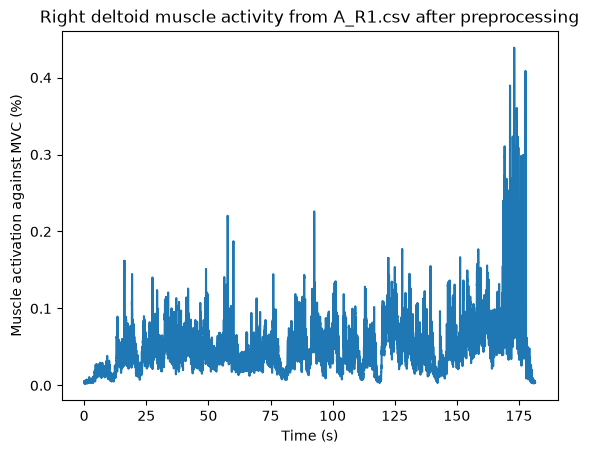

In [ ]:
# visualize EMG after preprocessing
plt.plot(emg_data[3]['time'], emg_data[3]['mid_delt_rt'])
plt.xlabel("Time (s)")
plt.ylabel("Muscle activation against MVC (%)")
plt.title(f"Right deltoid muscle activity from \"{emg_data[3]['filename']}\" after preprocessing")
plt.show()

# Create dataset
1. Split data into small segments and pair pose/emg data
2. Define PyTorch dataset
3. Split dataset (K-fold cross validation, LOSO)

In [44]:
from pose_to_emg_dataset import segment_and_pair_data, PoseToEMGDataset

In [48]:
# choose segment length and split data into segments, and pair each pose/emg data segment
SEGMENT_LENGTH = 0.5 # seconds
pose_emg_segment_pairs = segment_and_pair_data(emg_data=emg_data, pose_data=pose_data, segment_length=SEGMENT_LENGTH)
print(f"Created {len(pose_emg_segment_pairs)} {SEGMENT_LENGTH}s pose-to-emg pairs.")

Created 2598 0.5s pose-to-emg pairs.


In [49]:
# instance dataset
VIDEO_FRAMERATE = 30 # fps
pose_segment_length = int(round(VIDEO_FRAMERATE * SEGMENT_LENGTH))
print("pose_segment_length:", pose_segment_length)

pose_to_emg_dataset = PoseToEMGDataset(pose_emg_segment_pairs, pose_segment_length)


pose_segment_length: 15
Kept 2598/2598 segments (100.00%)


In [ ]:
# dataset split